<a href="https://colab.research.google.com/github/yesyes123456553/Laboratory_Exam/blob/main/Canton_LaboratoryExam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Load and Explore the Dataset
We will start by importing the necessary libraries and loading the `telecom_churn.csv` dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/telecom_churn.csv')

# Display basic information
print("Dataset Shape:", df.shape)
print("\nDataset Columns & Types:")
display(df.info())
print("\nFirst 5 rows:")
display(df.head())


Dataset Shape: (3333, 21)

Dataset Columns & Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   state                   3333 non-null   object 
 1   account length          3333 non-null   int64  
 2   area code               3333 non-null   int64  
 3   phone number            3333 non-null   object 
 4   international plan      3333 non-null   object 
 5   voice mail plan         3333 non-null   object 
 6   number vmail messages   3333 non-null   int64  
 7   total day minutes       3333 non-null   float64
 8   total day calls         3333 non-null   int64  
 9   total day charge        3333 non-null   float64
 10  total eve minutes       3333 non-null   float64
 11  total eve calls         3333 non-null   int64  
 12  total eve charge        3333 non-null   float64
 13  total night minutes     3333 non-null   f

None


First 5 rows:


,state,account length,area code,phone number,international plan,voice mail plan,number vmail messages,total day minutes,total day calls,total day charge,...,total eve calls,total eve charge,total night minutes,total night calls,total night charge,total intl minutes,total intl calls,total intl charge,customer service calls,churn
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


2. Target Variable Distribution
Let's check the distribution of our target variable `Churn` to see if we have an class imbalance issue.

In [3]:
# Print and visualize class distribution
print("Churn distribution counts:")
print(df['churn'].value_counts())
print("\nChurn distribution percentages:")
print(df['churn'].value_counts(normalize=True) * 100)

Churn distribution counts:
churn
False    2850
True      483
Name: count, dtype: int64

Churn distribution percentages:
churn
False    85.508551
True     14.491449
Name: proportion, dtype: float64


## 3. Data Preprocessing
We will clean and transform the dataset by:
1. Dropping non-predictive columns (`phone number`, `state`).
2. Enconding binary categorical variables (`international plan`, `voice mail plan`) to 0 and 1.
3. Splitting the dataset into features ($X$) and target ($y$).
4. Performing a train-test split (80-20).
5. Scaling numeric features to standardize their ranges.

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Drop non-predictive columns
df_clean = df.drop(columns=['phone number', 'state'])

# 2. Map binary categorical values to binary numeric values
binary_mapping = {'yes': 1, 'no': 0}
df_clean['international plan'] = df_clean['international plan'].map(binary_mapping)
df_clean['voice mail plan'] = df_clean['voice mail plan'].map(binary_mapping)

# 3. Separate features and target
X = df_clean.drop(columns=['churn'])
y = df_clean['churn'].astype(int)

# 4. Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Scale numeric columns
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing Complete.")
print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Preprocessing Complete.
Training set shape: (2666, 18)
Testing set shape: (667, 18)


## 4. Model Implementation & Training
We will implement and train three supervised classification algorithms:
- **Model A**: Logistic Regression (Highly interpretable baseline, adjusted for class imbalance)
- **Model B**: Decision Tree Classifier (Captures non-linear decision boundaries and feature interactions)
- **Model C**: Random Forest Classifier (An ensemble technique designed to improve predictive accuracy and prevent overfitting)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# --- Model A: Logistic Regression ---
print("=== Model A: Logistic Regression ===")
model_a = LogisticRegression(random_state=42, class_weight='balanced')
model_a.fit(X_train_scaled, y_train)
preds_a = model_a.predict(X_test_scaled)
probs_a = model_a.predict_proba(X_test_scaled)[:, 1]
print(classification_report(y_test, preds_a))
print(f"ROC AUC Score: {roc_auc_score(y_test, probs_a):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, preds_a))
print("\n" + "="*40 + "\n")

# --- Model B: Decision Tree Classifier ---
print("=== Model B: Decision Tree Classifier ===")
model_b = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced')
model_b.fit(X_train_scaled, y_train)
preds_b = model_b.predict(X_test_scaled)
probs_b = model_b.predict_proba(X_test_scaled)[:, 1]
print(classification_report(y_test, preds_b))
print(f"ROC AUC Score: {roc_auc_score(y_test, probs_b):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, preds_b))
print("\n" + "="*40 + "\n")

# --- Model C: Random Forest Classifier ---
print("=== Model C: Random Forest Classifier ===")
model_c = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model_c.fit(X_train_scaled, y_train)
preds_c = model_c.predict(X_test_scaled)
probs_c = model_c.predict_proba(X_test_scaled)[:, 1]
print(classification_report(y_test, preds_c))
print(f"ROC AUC Score: {roc_auc_score(y_test, probs_c):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, preds_c))
print("\n" + "="*40 + "\n")

# Keep the models dictionary structure for downstream evaluation cells
models = {
    "Logistic Regression": model_a,
    "Decision Tree": model_b,
    "Random Forest": model_c
}

=== Model A: Logistic Regression ===
              precision    recall  f1-score   support

           0       0.94      0.76      0.84       570
           1       0.35      0.73      0.47        97

    accuracy                           0.76       667
   macro avg       0.65      0.75      0.66       667
weighted avg       0.86      0.76      0.79       667

ROC AUC Score: 0.8143
Confusion Matrix:
[[436 134]
 [ 26  71]]


=== Model B: Decision Tree Classifier ===
              precision    recall  f1-score   support

           0       0.95      0.94      0.94       570
           1       0.65      0.72      0.69        97

    accuracy                           0.90       667
   macro avg       0.80      0.83      0.81       667
weighted avg       0.91      0.90      0.91       667

ROC AUC Score: 0.8034
Confusion Matrix:
[[533  37]
 [ 27  70]]


=== Model C: Random Forest Classifier ===
              precision    recall  f1-score   support

           0       0.95      0.98      0

## 5. Comparative Summary Table
We will extract the metrics (Accuracy, Precision, Recall, and F1-Score) for the churn class (Class 1) across all three models and present them in a formatted DataFrame.

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Initialize a list to hold metrics data
metrics_data = []

for name, model in models.items():
    preds = model.predict(X_test_scaled)

    # Calculate metrics (focusing on class 1 for precision, recall, and f1-score)
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, pos_label=1)
    rec = recall_score(y_test, preds, pos_label=1)
    f1 = f1_score(y_test, preds, pos_label=1)

    metrics_data.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall (Sensitivity)': rec,
        'F1-Score': f1
    })

# Create comparative summary table
summary_df = pd.DataFrame(metrics_data).set_index('Model').T
display(summary_df)

Model,Logistic Regression,Decision Tree,Random Forest
Accuracy,0.760120,0.904048,0.940030
Precision,0.346341,0.654206,0.870130
Recall (Sensitivity),0.731959,0.721649,0.690722
F1-Score,0.470199,0.686275,0.770115


## 6. ROC Curve Comparison
We will plot and compare the ROC (Receiver Operating Characteristic) curves for all three models to visually evaluate their trade-offs between true positive rate and false positive rate.

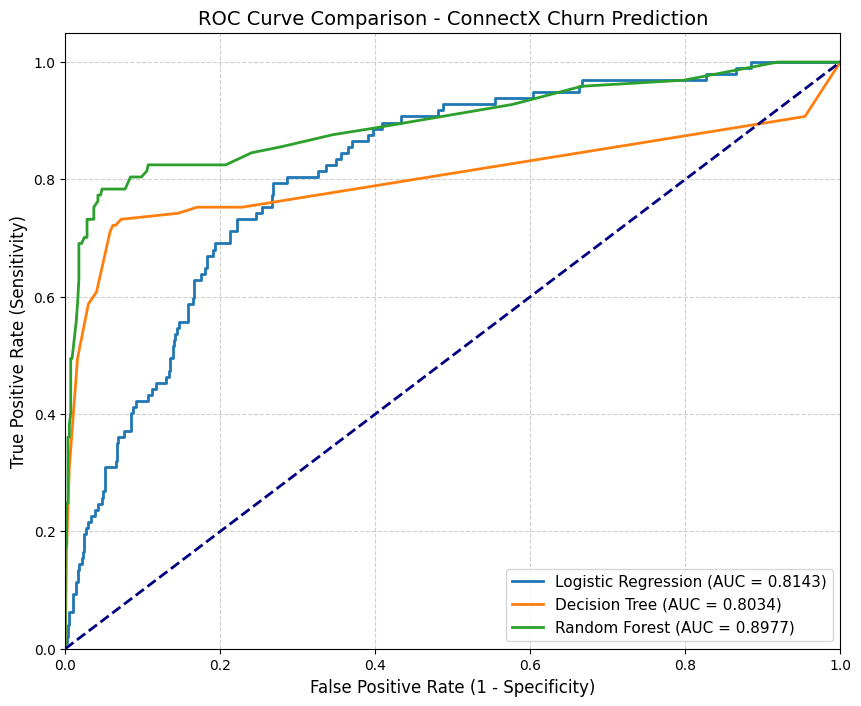

In [7]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(10, 8))

for name, model in models.items():
    probs = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.4f})', lw=2)

# Plot the diagonal baseline
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', lw=2)

# Customizations
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curve Comparison - ConnectX Churn Prediction', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()